# Tugas 2 — Visualisasi Data Deret Waktu

Visualisasi Data Lanjut (CAK7AGB4) · NIM 203012420009

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Baca data mentah (path relatif), semua kolom sebagai teks dulu
raw = pd.read_csv("../datasets/203012420009_operasional.csv", dtype=str)
raw.shape

(5647, 6)

## Bagian A — Pemeriksaan awal

### A0. Struktur dan tipe data

In [3]:
raw.head(10)

,tanggal,cabang,transaksi,omzet,keluhan,staf_aktif
0,2025-10-17,Tasikmalaya,226,17100700.0,18,2.0
1,2024-09-30,Bekasi,269,21995700.0,14,3.0
2,2025-02-05,Bekasi,310,25070900.0,17,5.0
3,2025-03-06,Garut,312,24489600.0,12,2.0
4,2024-02-22,Cirebon,178,14449500.0,13,3.0
5,2024-06-01,Tasikmalaya,248,19284800.0,9,3.0
6,2024-04-06,Cirebon,254,20341000.0,12,2.0
7,2025-01-08,Cimahi,179,13627500.0,7,NaN
8,2025-07-01,Depok,384,31789200.0,15,4.0
9,2024-10-03,Sumedang,102,8244600.0,5,2.0


In [4]:
# Konversi tipe; nilai yang gagal dikonversi menjadi NaN
df = raw.copy()
df["tanggal"] = pd.to_datetime(df["tanggal"], errors="coerce")
NUM = ["transaksi", "omzet", "keluhan", "staf_aktif"]
for k in NUM:
    df[k] = pd.to_numeric(df[k], errors="coerce")

# Nilai yang gagal dikonversi (di luar yang memang kosong)
gagal = {k: int((df[k].isna() & raw[k].notna()).sum()) for k in ["tanggal"] + NUM}
gagal

{'tanggal': 0, 'transaksi': 0, 'omzet': 0, 'keluhan': 0, 'staf_aktif': 0}

In [5]:
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5647 entries, 0 to 5646
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   tanggal     5647 non-null   datetime64[ns]
 1   cabang      5647 non-null   object        
 2   transaksi   5647 non-null   int64         
 3   omzet       5647 non-null   float64       
 4   keluhan     5647 non-null   int64         
 5   staf_aktif  5580 non-null   float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(1)
memory usage: 264.8+ KB


,count,mean,min,25%,50%,75%,max,std
tanggal,5647,2024-12-21 05:12:37.995396096,2024-01-01 00:00:00,2024-06-27 00:00:00,2024-12-21 00:00:00,2025-06-17 00:00:00,2025-12-11 00:00:00,NaN
transaksi,5647.0,366.875863,0.0,179.0,269.0,373.0,20617.0,1025.782485
omzet,5647.0,22196056.578714,0.0,13834000.0,20865300.0,29000750.0,80904300.0,10586247.750114
keluhan,5647.0,15.44289,0.0,9.0,14.0,20.0,71.0,8.633332
staf_aktif,5580.0,3.273297,2.0,2.0,3.0,4.0,7.0,1.232166


In [6]:
# Nilai kosong per kolom
hilang = df.isna().sum()
pd.DataFrame({"jumlah": hilang, "persen": (hilang / len(df) * 100).round(2)})

,jumlah,persen
tanggal,0,0.00
cabang,0,0.00
transaksi,0,0.00
omzet,0,0.00
keluhan,0,0.00
staf_aktif,67,1.19


In [7]:
# Kolom hitungan yang seharusnya bilangan bulat
{k: int((df[k].dropna() % 1 != 0).sum()) for k in NUM}

{'transaksi': 0, 'omzet': 0, 'keluhan': 0, 'staf_aktif': 0}

In [8]:
# Daftar cabang dan jumlah baris
df["cabang"].value_counts()

cabang
Cimahi         712
Sumedang       709
Bekasi         707
Garut          707
Bandung        705
Depok          704
Tasikmalaya    703
Cirebon        700
Name: count, dtype: int64

### A1. Rentang tanggal dan kelengkapan

In [9]:
# Rentang tanggal per cabang
rentang = df.groupby("cabang")["tanggal"].agg(awal="min", akhir="max", baris="size", tanggal_unik="nunique")
rentang["hari_kalender"] = (rentang["akhir"] - rentang["awal"]).dt.days + 1
rentang

,awal,akhir,baris,tanggal_unik,hari_kalender
cabang,,,,,
Bandung,2024-01-01,2025-12-11,705,701,711
Bekasi,2024-01-01,2025-12-11,707,703,711
Cimahi,2024-01-01,2025-12-11,712,708,711
Cirebon,2024-01-01,2025-12-11,700,698,711
Depok,2024-01-02,2025-12-11,704,699,710
Garut,2024-01-01,2025-12-11,707,704,711
Sumedang,2024-01-01,2025-12-11,709,705,711
Tasikmalaya,2024-01-01,2025-12-11,703,701,711


In [10]:
# Grid lengkap tanggal x cabang untuk melihat tanggal yang tidak punya baris
semua_tgl = pd.date_range(df["tanggal"].min(), df["tanggal"].max(), freq="D")
grid = pd.MultiIndex.from_product([semua_tgl, sorted(df["cabang"].unique())], names=["tanggal", "cabang"])
ada = df.groupby(["tanggal", "cabang"]).size().reindex(grid, fill_value=0).rename("n_baris")

print("total pasangan tanggal-cabang:", len(grid))
ada.value_counts().sort_index()

total pasangan tanggal-cabang: 5688


n_baris
0      69
1    5591
2      28
Name: count, dtype: int64

In [11]:
# Tanggal tanpa baris, diringkas menjadi blok berurutan per cabang
kosong = ada[ada == 0].reset_index()[["tanggal", "cabang"]].sort_values(["cabang", "tanggal"])
kosong["blok"] = (kosong.groupby("cabang")["tanggal"].diff().dt.days != 1).cumsum()
blok_kosong = (kosong.groupby(["cabang", "blok"])["tanggal"]
               .agg(mulai="min", selesai="max", hari="size")
               .reset_index(drop=False).drop(columns="blok"))
blok_kosong

,cabang,mulai,selesai,hari
0,Bandung,2024-01-11,2024-01-11,1
1,Bandung,2024-04-18,2024-04-19,2
2,Bandung,2024-07-05,2024-07-05,1
3,Bandung,2024-11-28,2024-11-28,1
4,Bandung,2024-12-28,2024-12-28,1
...,...,...,...,...
62,Tasikmalaya,2025-05-20,2025-05-20,1
63,Tasikmalaya,2025-08-07,2025-08-07,1
64,Tasikmalaya,2025-09-02,2025-09-02,1
65,Tasikmalaya,2025-10-25,2025-10-25,1


In [12]:
# Jumlah baris per bulan per cabang
df.pivot_table(index=df["tanggal"].dt.to_period("M"), columns="cabang", values="transaksi", aggfunc="size")

cabang,Bandung,Bekasi,Cimahi,Cirebon,Depok,Garut,Sumedang,Tasikmalaya
tanggal,,,,,,,,
2024-01,30,31,31,29,28,31,32,30
2024-02,29,29,28,28,30,29,29,29
2024-03,31,31,31,31,31,31,30,31
2024-04,28,30,30,29,29,30,30,31
2024-05,31,30,31,30,31,31,31,30
2024-06,31,30,30,30,27,28,30,30
2024-07,30,32,32,31,31,31,31,31
2024-08,31,30,30,31,33,29,31,30
2024-09,30,30,30,28,31,30,30,30


In [13]:
# Jumlah baris per tanggal pada 30 hari terakhir
df[df["tanggal"] > df["tanggal"].max() - pd.Timedelta(days=30)].groupby("tanggal").size()

/tmp/user/1005/ipykernel_653859/2743737943.py:2: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  df[df["tanggal"] > df["tanggal"].max() - pd.Timedelta(days=30)].groupby("tanggal").size()


tanggal
2025-11-12    8
2025-11-13    8
2025-11-14    8
2025-11-15    8
2025-11-16    8
2025-11-17    8
2025-11-18    8
2025-11-19    7
2025-11-20    8
2025-11-21    9
2025-11-22    8
2025-11-23    8
2025-11-24    8
2025-11-25    8
2025-11-26    7
2025-11-27    8
2025-11-28    8
2025-11-29    8
2025-11-30    8
2025-12-01    8
2025-12-02    8
2025-12-03    8
2025-12-04    8
2025-12-05    8
2025-12-06    8
2025-12-07    8
2025-12-08    8
2025-12-09    8
2025-12-10    7
2025-12-11    8
dtype: int64

### A2. Duplikat

In [14]:
# Baris yang identik seluruh kolom
print("duplikat persis:", raw.duplicated().sum())

# Satu cabang dan satu tanggal yang punya lebih dari satu baris
kunci = df.duplicated(["tanggal", "cabang"], keep=False)
print("baris dengan kunci ganda:", kunci.sum())
df[kunci].sort_values(["cabang", "tanggal"])

duplikat persis: 0
baris dengan kunci ganda: 56


,tanggal,cabang,transaksi,omzet,keluhan,staf_aktif
242,2024-06-09,Bandung,578,43279700.0,44,6.0
1291,2024-06-09,Bandung,535,40094600.0,44,6.0
1523,2024-10-12,Bandung,624,44744000.0,33,5.0
5630,2024-10-12,Bandung,544,43577200.0,33,5.0
635,2024-12-04,Bandung,357,21603200.0,22,4.0
931,2024-12-04,Bandung,345,25281000.0,22,4.0
335,2025-02-03,Bandung,357,25819000.0,16,5.0
1866,2025-02-03,Bandung,312,27714700.0,16,5.0
3188,2024-01-25,Bekasi,196,15224100.0,10,3.0
3729,2024-01-25,Bekasi,215,17203900.0,10,3.0


### A3. Nilai nol, negatif, dan ekstrem

In [15]:
# Jumlah nilai nol dan negatif per kolom per cabang
pd.concat({
    "nol": df[NUM].eq(0).groupby(df["cabang"]).sum(),
    "negatif": df[NUM].lt(0).groupby(df["cabang"]).sum(),
}, axis=1)

nol                            negatif                \
            transaksi omzet keluhan staf_aktif transaksi omzet keluhan   
cabang                                                                   
Bandung             4     4       4          0         0     0       0   
Bekasi              3     3       3          0         0     0       0   
Cimahi              5     5       5          0         0     0       0   
Cirebon             8     8       8          0         0     0       0   
Depok               3     3       3          0         0     0       0   
Garut               5     5       6          0         0     0       0   
Sumedang            2     2       3          0         0     0       0   
Tasikmalaya         3     3       3          0         0     0       0   

                        
            staf_aktif  
cabang                  
Bandung              0  
Bekasi               0  
Cimahi               0  
Cirebon              0  
Depok                0  
Garut                0  
Sumedang             0  
Tasikmalaya          0

In [16]:
# Baris yang memiliki nilai nol di salah satu kolom
df[df[NUM].eq(0).any(axis=1)].sort_values(["cabang", "tanggal"])

,tanggal,cabang,transaksi,omzet,keluhan,staf_aktif
248,2024-09-04,Bandung,0,0.0,0,4.0
1821,2025-03-25,Bandung,0,0.0,0,5.0
271,2025-05-29,Bandung,0,0.0,0,5.0
3857,2025-08-24,Bandung,0,0.0,0,6.0
3150,2024-05-20,Bekasi,0,0.0,0,4.0
1042,2024-07-01,Bekasi,0,0.0,0,4.0
5018,2025-02-17,Bekasi,0,0.0,0,5.0
2037,2024-03-11,Cimahi,0,0.0,0,3.0
1999,2024-08-06,Cimahi,0,0.0,0,3.0
2919,2024-08-20,Cimahi,0,0.0,0,NaN


In [17]:
# Statistik transaksi per cabang
df.groupby("cabang")[NUM].describe(percentiles=[.01, .5, .99]).round(1)

transaksi                                                       \
                count    mean     std  min     1%    50%      99%      max   
cabang                                                                       
Bandung         705.0  1023.6  2623.3  0.0  236.2  440.0  15679.5  18766.0   
Bekasi          707.0   394.4   113.0  0.0  185.0  386.0    670.9    978.0   
Cimahi          712.0   294.6   816.7  0.0  129.1  249.0    431.4  20617.0   
Cirebon         700.0   279.6   417.6  0.0    0.0  254.0    446.2   9666.0   
Depok           704.0   344.7    92.6  0.0  186.0  338.5    568.0    829.0   
Garut           707.0   265.2   134.6  0.0   85.1  248.0    561.8    840.0   
Sumedang        709.0   132.0    36.2  0.0   70.1  128.0    225.0    326.0   
Tasikmalaya     703.0   202.2   361.4  0.0  100.0  179.0    302.0   8640.0   

             omzet              ... keluhan       staf_aktif                 \
             count        mean  ...     99%   max      count mean  std  min   
cabang                          ...                                           
Bandung      705.0  34474886.0  ...    50.0  71.0      692.0  5.3  0.7  3.0   
Bekasi       707.0  30827195.8  ...    44.0  64.0      702.0  4.3  0.7  3.0   
Cimahi       712.0  19913019.2  ...    26.0  34.0      708.0  3.0  0.6  2.0   
Cirebon      700.0  20119360.7  ...    26.0  35.0      694.0  2.9  0.6  2.0   
Depok        704.0  26908682.1  ...    35.0  41.0      692.0  4.0  0.7  2.0   
Garut        707.0  20758280.3  ...    20.0  24.0      697.0  2.2  0.4  2.0   
Sumedang     709.0  10269983.6  ...    17.0  22.0      703.0  2.1  0.2  2.0   
Tasikmalaya  703.0  14336632.3  ...    20.0  25.0      692.0  2.3  0.5  2.0   

                                 
              1%  50%  99%  max  
cabang                           
Bandung      4.0  5.0  7.0  7.0  
Bekasi       3.0  4.0  6.0  6.0  
Cimahi       2.0  3.0  4.0  5.0  
Cirebon      2.0  3.0  4.0  5.0  
Depok        3.0  4.0  5.0  6.0  
Garut        2.0  2.0  3.0  4.0  
Sumedang     2.0  2.0  3.0  3.0  
Tasikmalaya  2.0  2.0  4.0  4.0  

[8 rows x 32 columns]

In [18]:
# Nilai tertinggi tiap kolom dan rasionya terhadap median cabangnya
def teratas(kolom, n=15):
    med = df.groupby("cabang")[kolom].transform("median")
    out = df.assign(rasio_median=(df[kolom] / med).round(2))
    return out.nlargest(n, kolom)[["tanggal", "cabang", kolom, "rasio_median"]]

teratas("transaksi")

,tanggal,cabang,transaksi,rasio_median
1155,2025-08-23,Cimahi,20617,82.80
3868,2024-08-17,Bandung,18766,42.65
5526,2024-08-16,Bandung,18210,41.39
4774,2024-08-15,Bandung,17733,40.30
5153,2024-08-14,Bandung,17336,39.40
2442,2024-08-13,Bandung,16970,38.57
3642,2024-08-12,Bandung,16616,37.76
449,2024-08-11,Bandung,16257,36.95
3618,2024-08-10,Bandung,15701,35.68
3116,2024-08-09,Bandung,15164,34.46


In [19]:
teratas("omzet")

,tanggal,cabang,omzet,rasio_median
2812,2025-06-06,Bandung,80904300.0,2.42
668,2025-06-06,Bekasi,78209500.0,2.60
251,2025-06-06,Garut,69762400.0,3.66
1180,2025-06-06,Depok,65096500.0,2.49
5344,2025-06-28,Bandung,64051600.0,1.92
1703,2025-07-26,Bandung,62336100.0,1.87
1944,2025-05-03,Bandung,60854600.0,1.82
37,2025-04-26,Bandung,60421400.0,1.81
3269,2025-08-16,Bandung,60187700.0,1.80
1606,2025-06-06,Cirebon,59768000.0,3.04


In [20]:
teratas("keluhan")

,tanggal,cabang,keluhan,rasio_median
2812,2025-06-06,Bandung,71,2.73
668,2025-06-06,Bekasi,64,2.78
1488,2024-06-06,Bandung,54,2.08
959,2025-07-19,Bandung,51,1.96
1703,2025-07-26,Bandung,51,1.96
1758,2025-07-19,Bekasi,51,2.22
2853,2024-12-12,Bandung,51,1.96
2529,2024-06-15,Bandung,50,1.92
3382,2025-04-26,Bekasi,50,2.17
4332,2025-09-07,Bandung,50,1.92


### A4. Besaran turunan per cabang

In [21]:
# Omzet per transaksi dan keluhan per 1000 transaksi
df["omzet_per_trx"] = df["omzet"] / df["transaksi"]
df["keluhan_per_1000"] = df["keluhan"] / df["transaksi"] * 1000
df.groupby("cabang")[["omzet_per_trx", "keluhan_per_1000"]].describe(percentiles=[.01, .5, .99]).round(1)

omzet_per_trx                                               \
                    count     mean      std      min       1%      50%   
cabang                                                                   
Bandung             701.0  73493.3  17854.6   1506.3   2096.7  77582.9   
Bekasi              704.0  78127.7   3951.2  66959.1  69538.4  78085.4   
Cimahi              707.0  77738.7   5673.0   1408.6  67277.0  77980.3   
Cirebon             692.0  77647.0   5612.4   1437.5  68051.8  77902.0   
Depok               701.0  78016.9   3947.1  65797.5  68866.2  77944.2   
Garut               702.0  78117.6   3699.9  68150.6  69923.0  78001.7   
Sumedang            707.0  77845.7   3983.5  66803.1  68786.3  77890.9   
Tasikmalaya         700.0  77757.6   5574.4   2073.0  68496.2  78052.4   

                              keluhan_per_1000                                \
                 99%      max            count  mean   std   min    1%   50%   
cabang                                                                         
Bandung      87206.6  90249.9            701.0  58.1  18.6   0.9   1.5  60.0   
Bekasi       87117.3  91188.0            704.0  59.8  13.2  24.5  32.8  58.9   
Cimahi       87043.1  93370.8            707.0  53.4  16.1   1.0  18.2  53.0   
Cirebon      86315.9  89406.1            692.0  52.0  15.2   1.2  19.4  51.4   
Depok        87503.5  96814.7            701.0  55.0  13.7  17.8  27.1  53.5   
Garut        86633.0  90158.0            702.0  43.9  23.3   0.0   9.3  37.5   
Sumedang     86710.6  97112.1            707.0  58.0  22.4   0.0  11.5  56.2   
Tasikmalaya  86793.5  92285.2            700.0  56.8  18.6   1.0  12.8  56.2   

                           
               99%    max  
cabang                     
Bandung       89.9  121.2  
Bekasi        92.9  103.6  
Cimahi        96.0  115.4  
Cirebon       89.8  104.2  
Depok         88.8  102.2  
Garut        106.4  168.5  
Sumedang     111.1  151.5  
Tasikmalaya  105.3  143.8

In [22]:
# Median bulanan per cabang
def median_bulanan(kolom):
    return df.pivot_table(index=df["tanggal"].dt.to_period("M"), columns="cabang", values=kolom, aggfunc="median").round(1)

median_bulanan("transaksi")

cabang,Bandung,Bekasi,Cimahi,Cirebon,Depok,Garut,Sumedang,Tasikmalaya
tanggal,,,,,,,,
2024-01,279.5,224.0,162.0,155.0,213.5,101.0,86.5,122.5
2024-02,304.0,243.0,172.5,174.0,231.0,122.0,89.0,132.0
2024-03,346.0,282.0,189.0,195.0,261.0,130.0,100.5,148.0
2024-04,361.0,293.5,203.5,195.0,265.0,138.5,117.5,151.0
2024-05,381.0,331.0,237.0,215.0,294.0,147.0,118.0,162.0
2024-06,435.0,364.0,234.5,253.0,336.0,160.5,125.0,178.5
2024-07,5044.0,334.0,229.0,225.0,293.0,156.0,124.0,166.0
2024-08,12145.0,330.5,236.5,224.0,304.0,160.0,122.0,168.5
2024-09,379.0,339.0,216.0,218.0,299.0,151.5,110.5,159.5


In [23]:
median_bulanan("omzet_per_trx")

cabang,Bandung,Bekasi,Cimahi,Cirebon,Depok,Garut,Sumedang,Tasikmalaya
tanggal,,,,,,,,
2024-01,77530.8,77073.0,78183.3,77558.8,77719.4,77351.0,78102.4,76514.2
2024-02,77180.8,78754.1,79575.2,78866.9,77507.7,79508.5,78084.5,78778.1
2024-03,77653.2,78002.0,79068.0,77559.9,77833.5,78006.6,77717.3,78926.1
2024-04,77707.0,79156.3,77534.3,78217.3,79209.9,77980.6,78251.5,77427.9
2024-05,79769.3,77107.5,78577.5,77051.9,77408.5,77593.2,78418.9,77610.7
2024-06,76307.6,77978.4,76640.7,78535.2,78195.7,78071.7,77768.8,78076.4
2024-07,6021.1,75997.8,78783.1,77298.4,76919.3,78522.2,77762.5,78328.8
2024-08,3036.0,77260.2,78325.7,76989.8,76114.3,77163.9,77963.3,77578.0
2024-09,78328.6,78175.5,78558.5,77294.6,78213.6,76910.0,76919.1,78543.4


### A5. Plot deret mentah per cabang

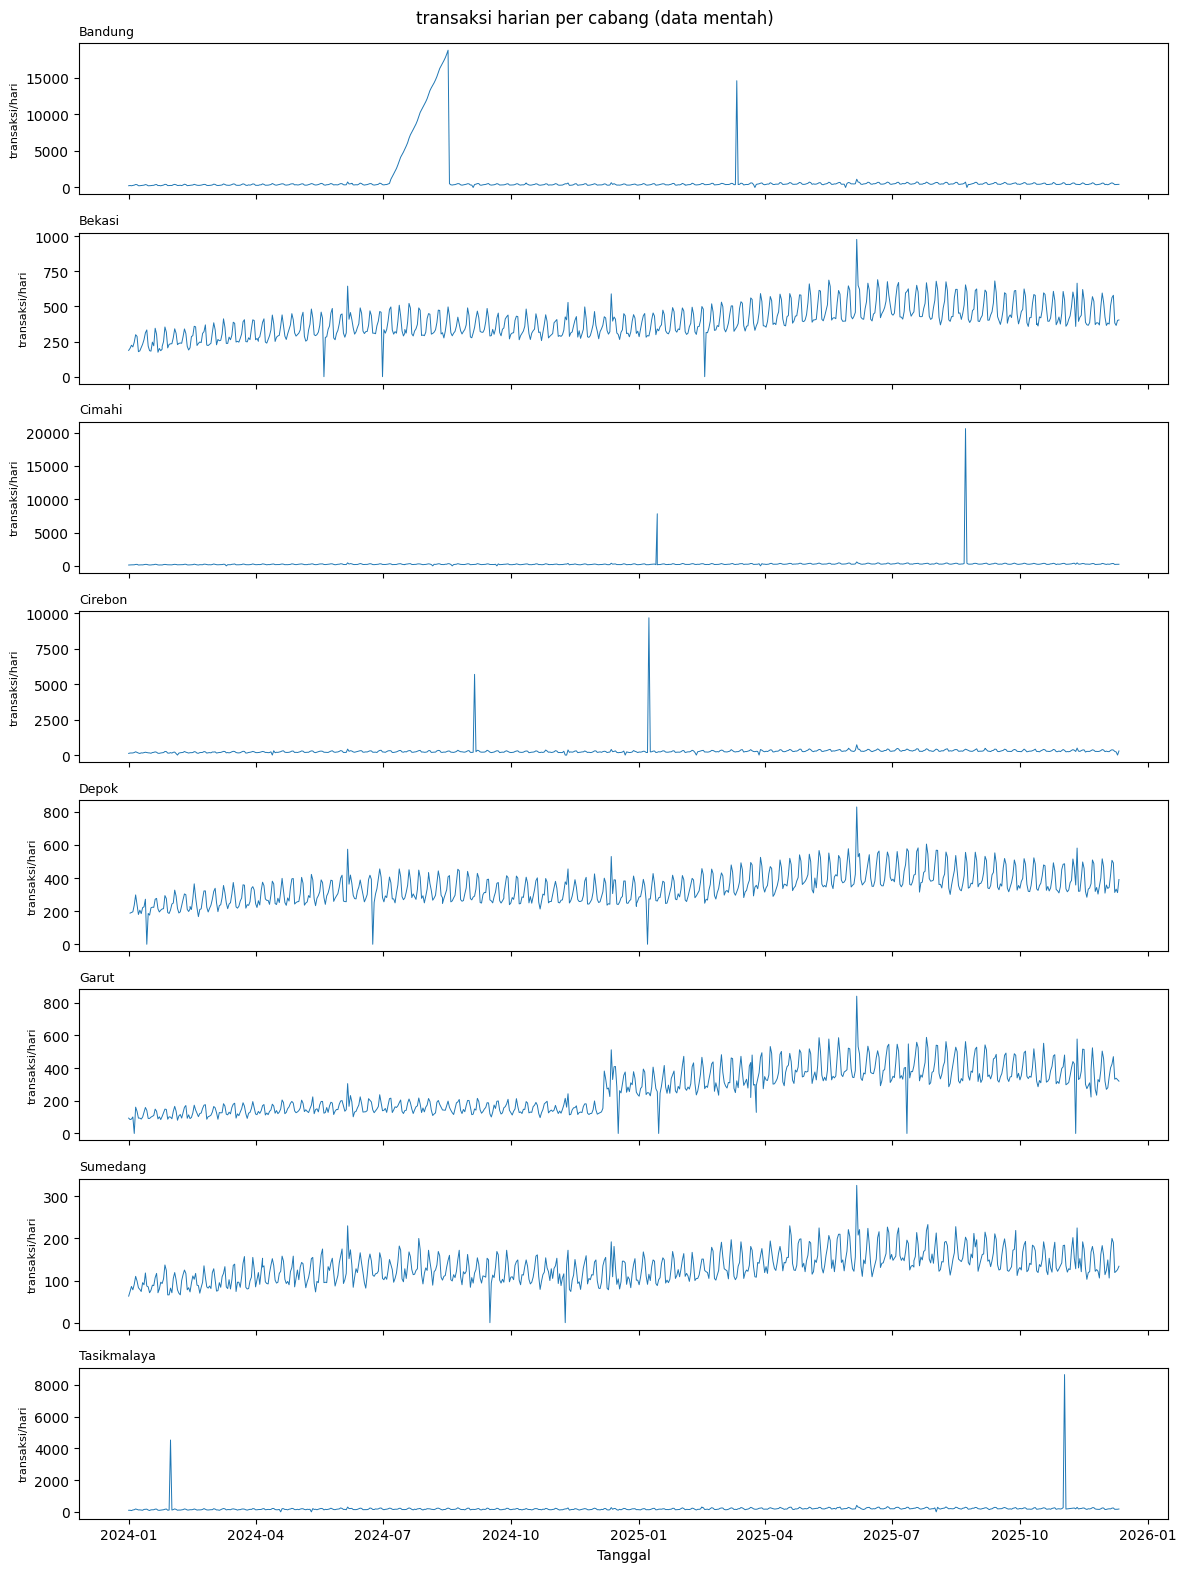

In [24]:
# Deret harian mentah satu kolom, satu panel per cabang
def plot_per_cabang(kolom, satuan, data=None):
    data = df if data is None else data
    cabang = sorted(data["cabang"].unique())
    fig, axes = plt.subplots(len(cabang), 1, figsize=(12, 2 * len(cabang)), sharex=True)
    for ax, c in zip(axes, cabang):
        s = data[data["cabang"] == c].sort_values("tanggal")
        ax.plot(s["tanggal"], s[kolom], lw=0.7)
        ax.set_title(c, loc="left", fontsize=9)
        ax.set_ylabel(satuan, fontsize=8)
    axes[-1].set_xlabel("Tanggal")
    fig.suptitle(f"{kolom} harian per cabang (data mentah)")
    fig.tight_layout()
    plt.show()

plot_per_cabang("transaksi", "transaksi/hari")

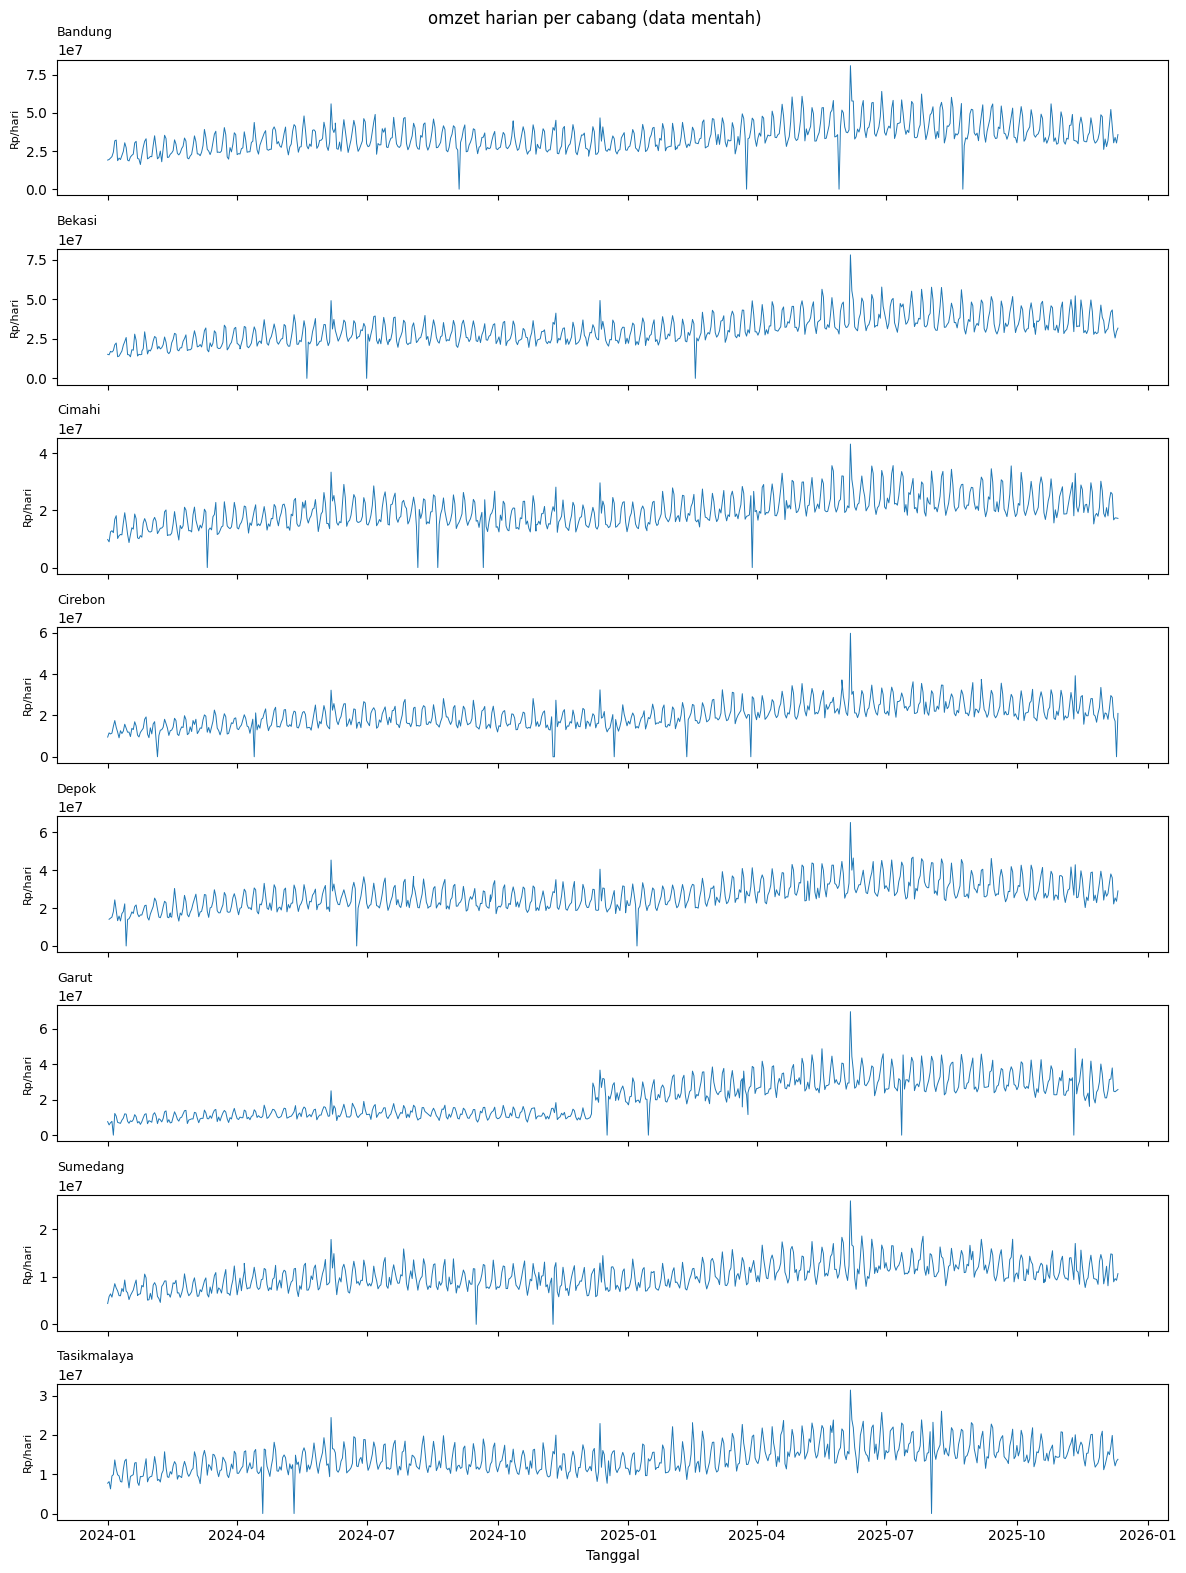

In [25]:
plot_per_cabang("omzet", "Rp/hari")

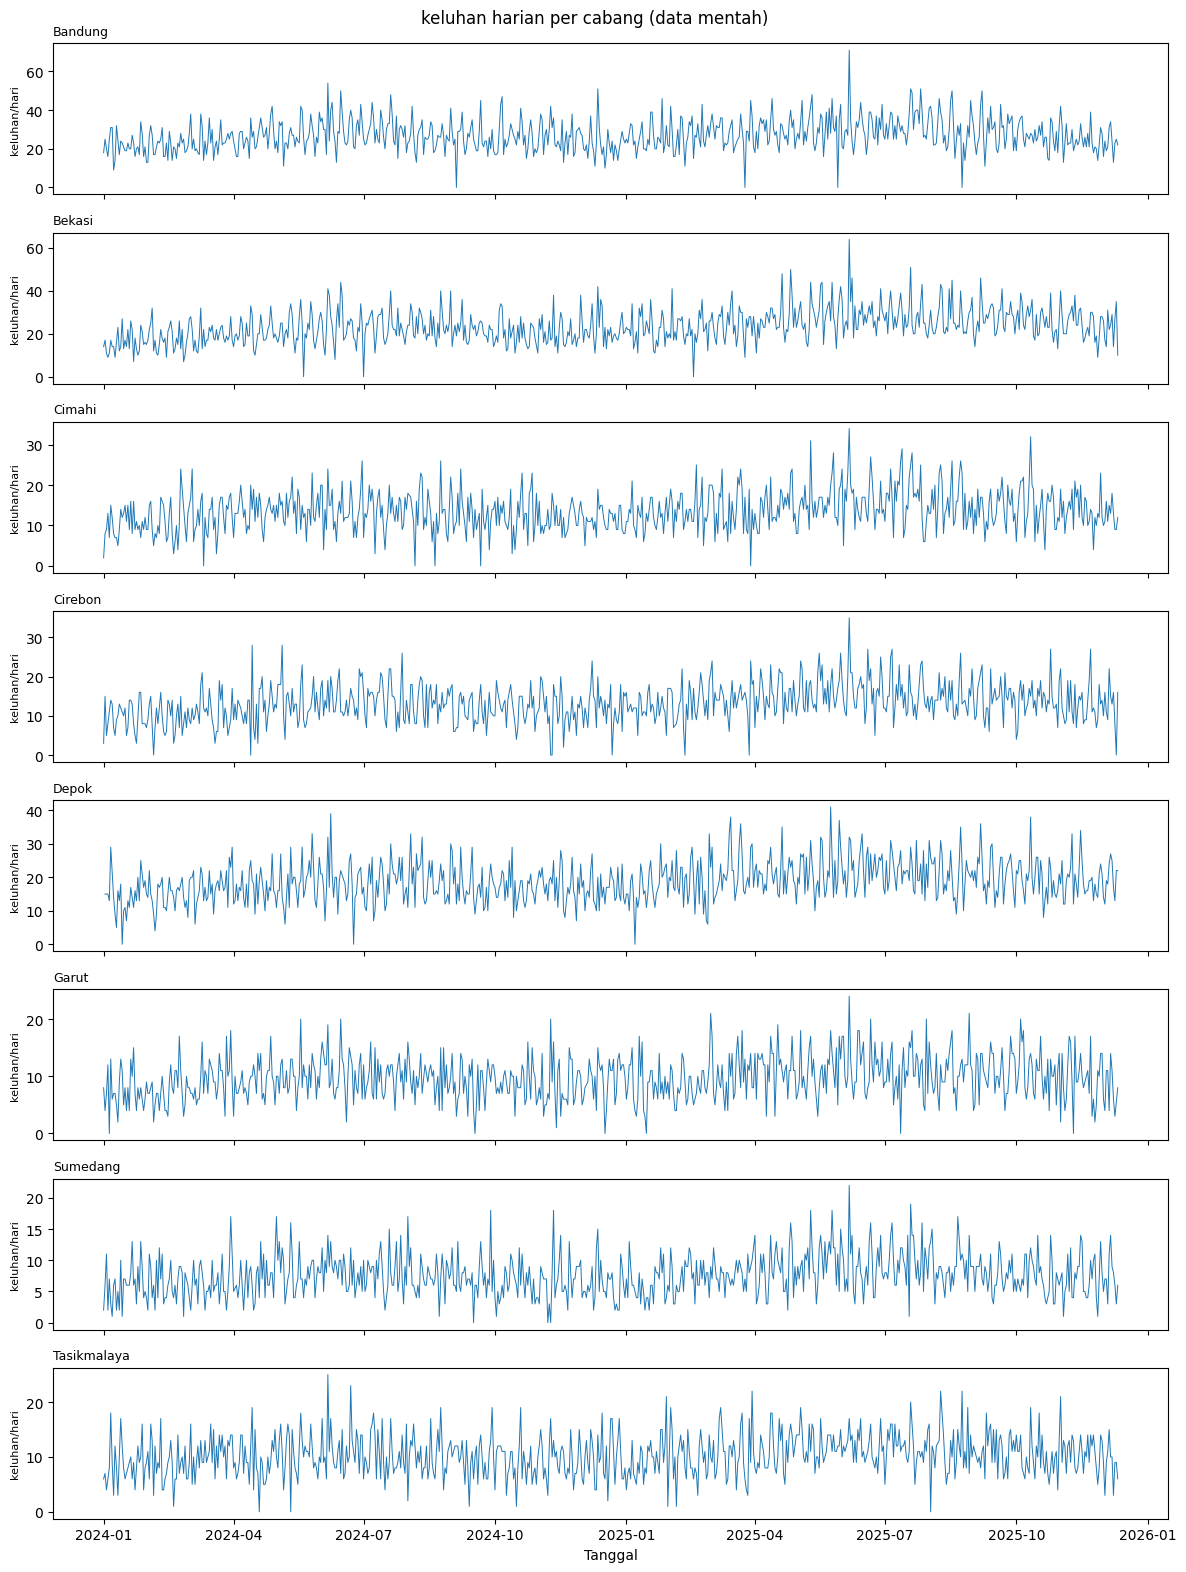

In [26]:
plot_per_cabang("keluhan", "keluhan/hari")

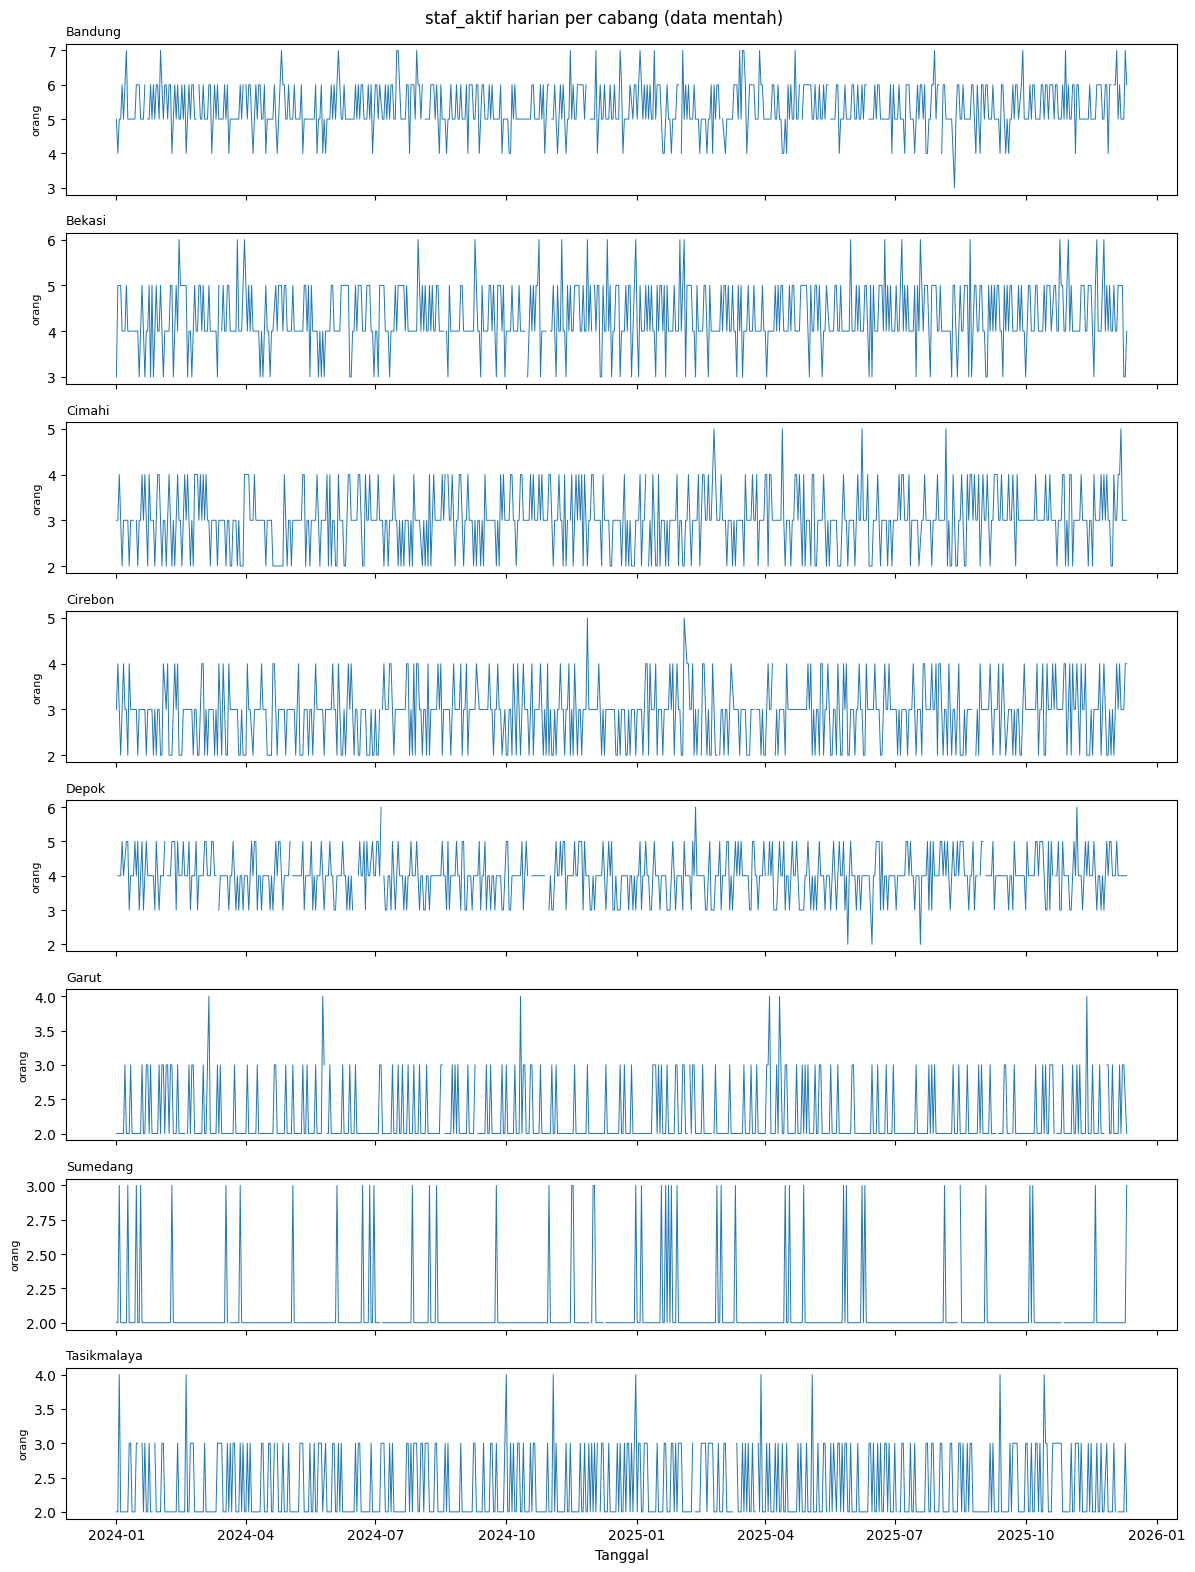

In [27]:
plot_per_cabang("staf_aktif", "orang")

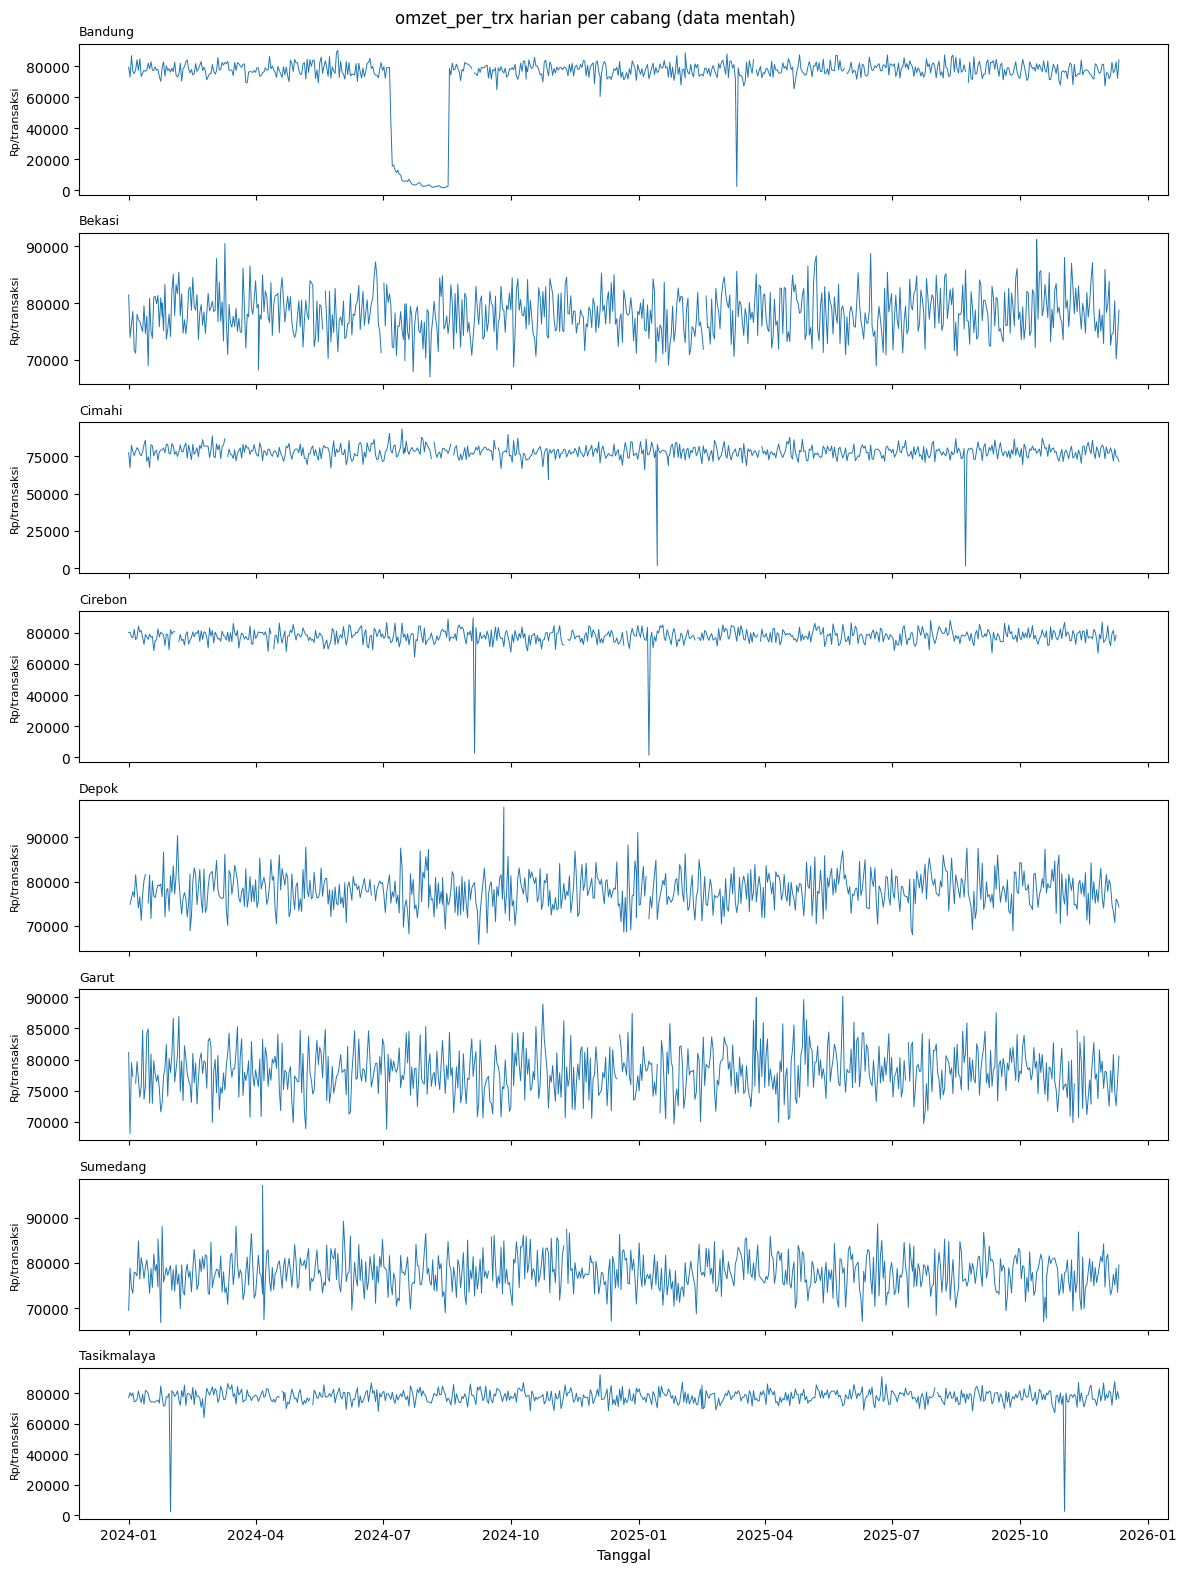

In [28]:
plot_per_cabang("omzet_per_trx", "Rp/transaksi")

## Bagian A — Cleaning

Urutan: stempel ganda → kumulatif → lonjakan mustahil → pergeseran level → tanggal hilang → flag (hari nol, promo) → periode belum lengkap.

In [29]:
# Data kerja dari kolom asli; dampak tiap langkah dicatat ke `log`
bersih = df[["tanggal", "cabang"] + NUM].copy()
log = []

def catat(cakupan, masalah, n, basis=len(df)):
    log.append({"cakupan": cakupan, "masalah": masalah, "terdampak": int(n),
                "persen": round(n / basis * 100, 2)})

### A6. Stempel ganda

In [30]:
# keluhan & staf_aktif identik di setiap pasangan; transaksi & omzet bertentangan
g = bersih[bersih.duplicated(["tanggal", "cabang"], keep=False)].groupby(["tanggal", "cabang"])
print("pasangan:", g.ngroups,
      "| keluhan identik:", (g["keluhan"].nunique() == 1).all(),
      "| staf identik:", (g["staf_aktif"].nunique(dropna=False) == 1).all())

pasangan: 28 | keluhan identik: True | staf identik: True


In [31]:
# Satu baris per tanggal-cabang; transaksi & omzet pasangan ganda dikosongkan
bersih = (bersih.groupby(["tanggal", "cabang"], as_index=False)
          .agg(transaksi=("transaksi", "first"), omzet=("omzet", "first"),
               keluhan=("keluhan", "first"), staf_aktif=("staf_aktif", "first"),
               n=("transaksi", "size")))
ganda = bersih["n"] > 1
bersih.loc[ganda, ["transaksi", "omzet"]] = np.nan
bersih = bersih.drop(columns="n")
catat("transaksi, omzet; semua cabang", "Stempel ganda", ganda.sum() * 2)
print("baris setelah digabung:", len(bersih))

baris setelah digabung: 5619


### A7. Periode kumulatif

In [32]:
# transaksi Bandung naik setiap hari selama blok, omzet tetap normal
KUM_CABANG, KUM_AWAL, KUM_AKHIR = "Bandung", "2024-07-07", "2024-08-17"
m = (bersih["cabang"] == KUM_CABANG) & bersih["tanggal"].between(KUM_AWAL, KUM_AKHIR)
blok = bersih[m].sort_values("tanggal")
selisih = blok["transaksi"].diff()

# Pembanding: Bandung normal sebelum dan sesudah blok
normal = bersih[(bersih["cabang"] == KUM_CABANG) & ~m & (bersih["transaksi"] > 0)
                & bersih["tanggal"].between("2024-06-01", "2024-09-30")]["transaksi"]
print("hari:", m.sum(), "| naik tiap hari:", (selisih.dropna() > 0).all())
pd.DataFrame({"selisih_blok": selisih.describe(), "bandung_normal": normal.describe()}).round(0)

hari: 42 | naik tiap hari: True


,selisih_blok,bandung_normal
count,41.0,77.0
mean,430.0,425.0
std,82.0,86.0
min,332.0,313.0
25%,363.0,356.0
50%,398.0,393.0
75%,482.0,503.0
max,605.0,749.0


In [33]:
# Pulihkan dengan selisih hari ke hari; hari pertama NaN karena pembandingnya tidak ada
bersih.loc[blok.index, "transaksi"] = selisih
catat(f"transaksi, {KUM_CABANG} {KUM_AWAL} s.d. {KUM_AKHIR}", "Periode kumulatif", m.sum())

### A8. Lonjakan mustahil

In [34]:
# Transaksi melonjak tanpa diikuti omzet: omzet per transaksi jatuh jauh di bawah normal
opt = bersih["omzet"] / bersih["transaksi"]
print("omzet/transaksi persentil 1%, 50%:", opt.quantile([.01, .5]).round(0).tolist())
mustahil = opt < 40_000
bersih.loc[mustahil, ["tanggal", "cabang", "transaksi", "omzet", "keluhan"]].assign(omzet_per_trx=opt[mustahil].round(0))

omzet/transaksi persentil 1%, 50%: [68834.0, 77975.0]


,tanggal,cabang,transaksi,omzet,keluhan,omzet_per_trx
239,2024-01-31,Tasikmalaya,4522.0,9374100.0,9,2073.0
1956,2024-09-05,Cirebon,5684.0,14840100.0,7,2611.0
2949,2025-01-08,Cirebon,9666.0,13895200.0,12,1438.0
3443,2025-03-12,Bandung,14592.0,32378100.0,22,2219.0
4744,2025-08-23,Cimahi,20617.0,29041800.0,26,1409.0
5310,2025-11-02,Tasikmalaya,8640.0,20666000.0,9,2392.0


In [35]:
bersih.loc[mustahil, "transaksi"] = np.nan
catat("transaksi; 6 tanggal di 4 cabang", "Lonjakan mustahil", mustahil.sum())

### A9. Pergeseran level Garut

In [36]:
# Faktor = rasio Garut/rata-rata cabang lain, 90 hari sesudah dibanding sebelum titik geser
GESER = pd.Timestamp("2024-12-07")

def faktor(kolom, hari=90):
    p = bersih[bersih[kolom] > 0].pivot_table(index="tanggal", columns="cabang", values=kolom)
    r = p["Garut"] / p.drop(columns="Garut").mean(axis=1)
    pra = r[GESER - np.timedelta64(hari, "D"):GESER - np.timedelta64(1, "D")].median()
    pasca = r[GESER:GESER + np.timedelta64(hari, "D")].median()
    return pasca / pra

FAKTOR = {k: round(faktor(k), 3) for k in NUM}
FAKTOR

{'transaksi': np.float64(1.98),
 'omzet': np.float64(2.043),
 'keluhan': np.float64(1.002),
 'staf_aktif': np.float64(1.029)}

In [37]:
# Hanya transaksi & omzet yang ikut berlipat; keluhan & staf tetap
m = (bersih["cabang"] == "Garut") & (bersih["tanggal"] >= GESER)
bersih.loc[m, "transaksi"] = (bersih.loc[m, "transaksi"] / FAKTOR["transaksi"]).round()
bersih.loc[m, "omzet"] = bersih.loc[m, "omzet"] / FAKTOR["omzet"]
catat(f"transaksi, omzet; Garut sejak {GESER:%Y-%m-%d}", "Pergeseran level", m.sum())

### A10. Tanggal hilang

In [38]:
# Lengkapi grid tanggal x cabang (dari A1); baris baru dibiarkan NaN
bersih["tanggal_hilang"] = False
bersih = bersih.set_index(["tanggal", "cabang"]).reindex(grid).reset_index()
bersih["tanggal_hilang"] = bersih["tanggal_hilang"].isna()
catat("semua kolom; semua cabang", "Tanggal hilang", bersih["tanggal_hilang"].sum(), basis=len(grid))
bersih.shape

(5688, 7)

### A11. Hari nol dan hari promo

In [39]:
# Hari nol dipertahankan, hanya diberi flag
bersih["hari_nol"] = bersih[["transaksi", "omzet", "keluhan"]].eq(0).all(axis=1)
catat("transaksi, omzet, keluhan; semua cabang", "Hari nol", bersih["hari_nol"].sum())

In [40]:
# Kenaikan transaksi terhadap median 15 hari cabangnya, dirangkum per tanggal
s = bersih.sort_values(["cabang", "tanggal"])
s = s.assign(naik=s["transaksi"] / s.groupby("cabang")["transaksi"]
             .transform(lambda x: x.rolling(15, center=True, min_periods=8).median()))
naik = s.groupby("tanggal")["naik"].agg(median="median", terendah="min", cabang="count")
naik.assign(hari=naik.index.day_name()).nlargest(8, "median").round(2)

,median,terendah,cabang,hari
tanggal,,,,
2025-06-06,2.06,1.93,8,Friday
2024-12-12,1.83,1.70,8,Thursday
2024-06-06,1.82,1.73,8,Thursday
2024-11-11,1.66,1.56,8,Monday
2025-11-11,1.63,1.39,7,Tuesday
2024-01-06,1.45,1.28,8,Saturday
2025-03-22,1.44,1.35,7,Saturday
2024-06-15,1.43,1.20,8,Saturday


In [41]:
# Tanggal kembar dengan kenaikan serentak di semua cabang dianggap promo (nilai dipertahankan)
PROMO = pd.to_datetime(["2024-06-06", "2024-11-11", "2024-12-12", "2025-06-06", "2025-11-11"])
bersih["promo"] = bersih["tanggal"].isin(PROMO)
catat("semua kolom; 5 tanggal promo", "Lonjakan nyata (dipertahankan)",
      (bersih["promo"] & ~bersih["tanggal_hilang"]).sum())

### A12. staf_aktif kosong dan periode belum lengkap

In [42]:
# staf_aktif tidak dipakai di Bagian B, dibiarkan NaN
catat("staf_aktif; semua cabang", "Nilai kosong", df["staf_aktif"].isna().sum())

# Desember 2025 baru 11 hari: dikeluarkan dari agregat bulanan dan angka tren
AKHIR_LENGKAP = pd.Timestamp("2025-11-30")
catat("semua kolom; 2025-12-01 s.d. 2025-12-11", "Periode belum lengkap",
      (df["tanggal"] > AKHIR_LENGKAP).sum())

### A13. Ringkasan

In [43]:
# Bahan tabel temuan
pd.DataFrame(log)

,cakupan,masalah,terdampak,persen
0,"transaksi, omzet; semua cabang",Stempel ganda,56,0.99
1,"transaksi, Bandung 2024-07-07 s.d. 2024-08-17",Periode kumulatif,42,0.74
2,transaksi; 6 tanggal di 4 cabang,Lonjakan mustahil,6,0.11
3,"transaksi, omzet; Garut sejak 2024-12-07",Pergeseran level,368,6.52
4,semua kolom; semua cabang,Tanggal hilang,69,1.21
5,"transaksi, omzet, keluhan; semua cabang",Hari nol,33,0.58
6,semua kolom; 5 tanggal promo,Lonjakan nyata (dipertahankan),39,0.69
7,staf_aktif; semua cabang,Nilai kosong,67,1.19
8,semua kolom; 2025-12-01 s.d. 2025-12-11,Periode belum lengkap,87,1.54


In [44]:
# Cek akhir data bersih
print("baris:", len(bersih), "| kunci unik:", not bersih.duplicated(["tanggal", "cabang"]).any())
print("omzet/transaksi min-maks:", (bersih["omzet"] / bersih["transaksi"]).replace(np.inf, np.nan).agg(["min", "max"]).round(0).tolist())
bersih[NUM].isna().sum()

baris: 5688 | kunci unik: True
omzet/transaksi min-maks: [64034.0, 93371.0]


transaksi     104
omzet          97
keluhan        69
staf_aktif    136
dtype: int64

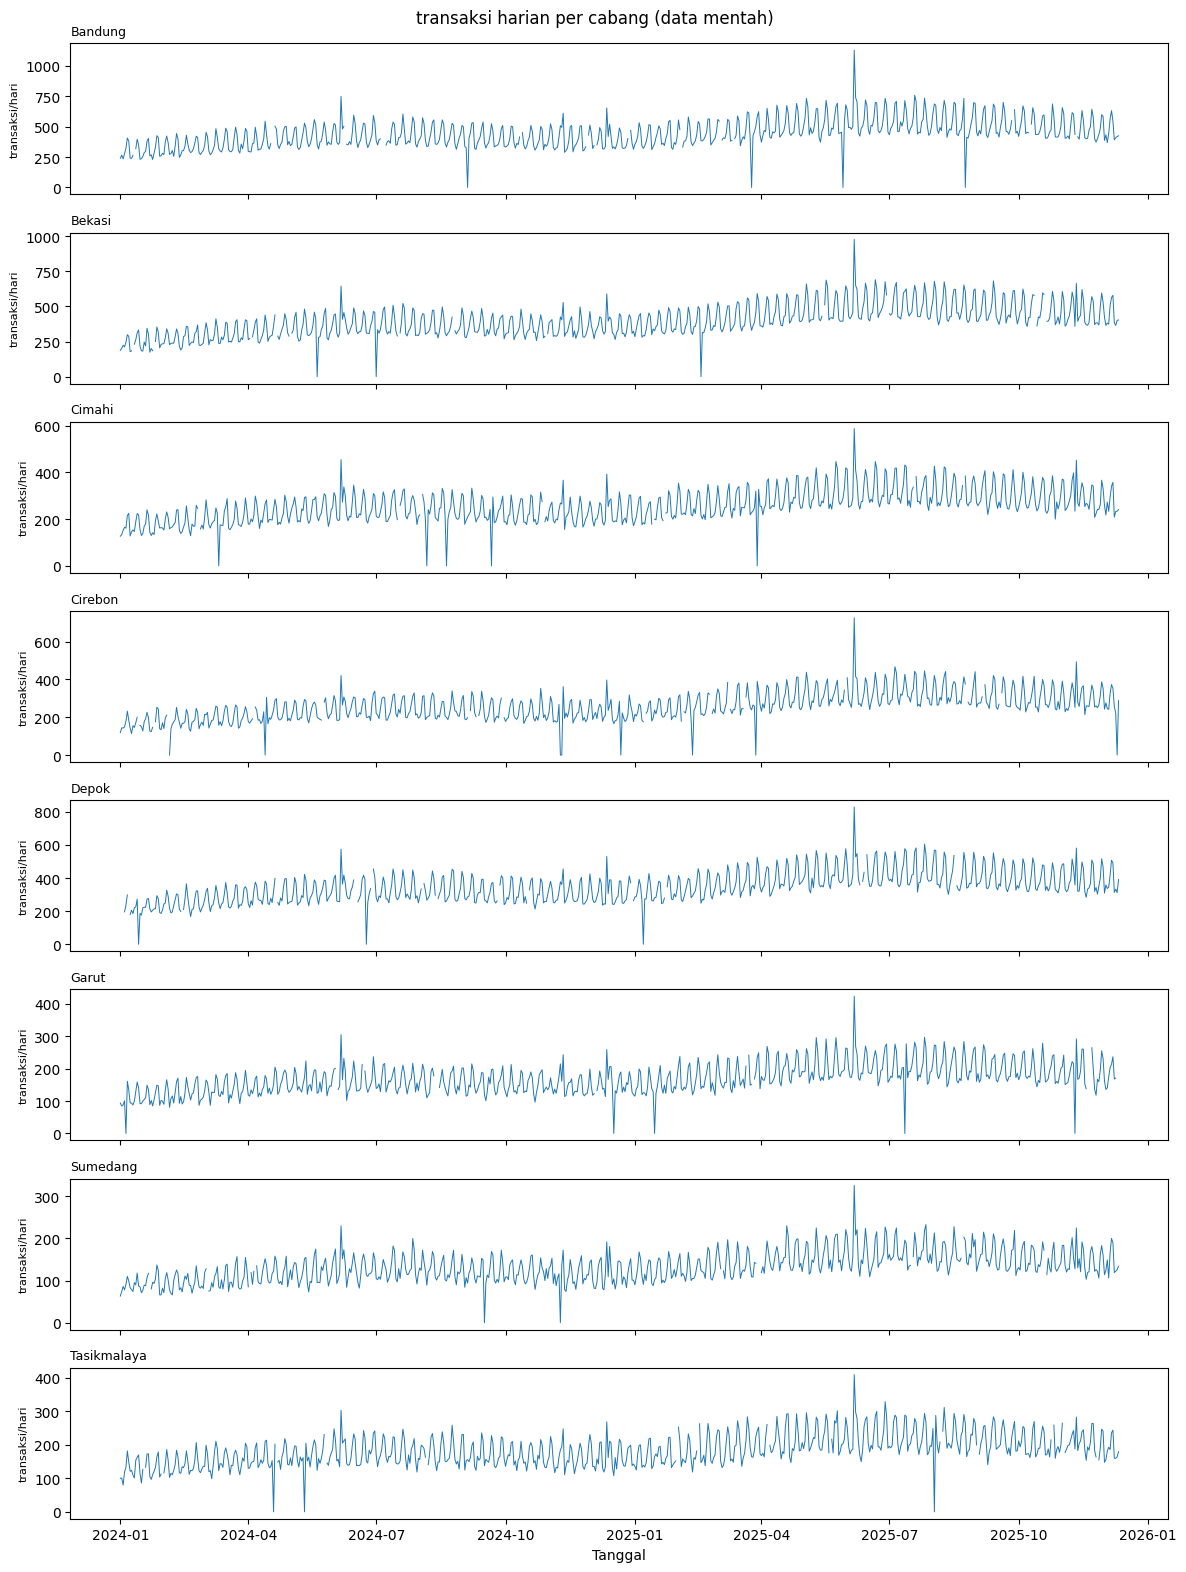

In [45]:
plot_per_cabang("transaksi", "transaksi/hari", data=bersih)

## Bagian B1 — Komponen deret waktu transaksi harian

In [46]:
from statsmodels.tsa.seasonal import STL

# Gaya gambar: warna seri, grid tipis, ukuran huruf terbaca saat dicetak
BIRU, ORANYE, ABU, TEKS = "#2a78d6", "#eb6834", "#8a8984", "#52514e"
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6})
FIG = Path("figure")
FIG.mkdir(exist_ok=True)
HARI = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
BULAN = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

/home/bdo/.local/lib/python3.12/site-packages/statsmodels/tools/tools.py:6: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.0)
  import scipy.linalg


### B1.1 Deret total harian

In [47]:
# Input STL: hari nol dianggap kosong, NaN diisi interpolasi linear per cabang, lalu dijumlahkan
def lebar(kolom):
    return bersih.pivot(index="tanggal", columns="cabang", values=kolom)

trx = lebar("transaksi").mask(lebar("hari_nol").astype(bool))
diisi = trx.isna().any(axis=1)
total = trx.interpolate(limit_direction="both").sum(axis=1)
print("hari dengan isian:", diisi.sum(), "dari", len(total))

hari dengan isian: 125 dari 711


In [48]:
# Amplitudo mingguan membesar seiring level, rasionya stabil -> musiman multiplikatif
cek = STL(total, period=7, robust=True).fit()
kuartal = pd.DataFrame({"amplitudo": cek.seasonal.resample("QE").agg(lambda s: s.max() - s.min()),
                        "level": cek.trend.resample("QE").mean()})
kuartal["rasio"] = kuartal["amplitudo"] / kuartal["level"]
kuartal.round(2)

,amplitudo,level,rasio
tanggal,,,
2024-03-31,875.52,1586.38,0.55
2024-06-30,1017.46,1988.07,0.51
2024-09-30,1057.24,2060.14,0.51
2024-12-31,921.03,1918.66,0.48
2025-03-31,1134.40,2160.31,0.53
2025-06-30,1347.10,2642.37,0.51
2025-09-30,1319.71,2695.21,0.49
2025-12-31,1160.91,2462.62,0.47


### B1.2 Dekomposisi STL

In [49]:
# STL pada log: periode 7 hari, jendela tren 91 hari, robust agar hari promo tidak menarik tren/musiman
stl = STL(np.log(total), period=7, trend=91, robust=True).fit()
komp = pd.DataFrame({"total": total, "tren": np.exp(stl.trend),
                     "musiman": np.exp(stl.seasonal), "sisa": np.exp(stl.resid)})

# Faktor musiman per hari (% terhadap tren)
faktor_hari = (komp["musiman"].groupby(komp.index.dayofweek).mean() - 1) * 100
faktor_hari.index = HARI
faktor_hari.round(1)

Senin    -14.3
Selasa   -16.6
Rabu     -12.4
Kamis     -7.9
Jumat      7.0
Sabtu     31.0
Minggu    23.8
Name: musiman, dtype: float64

In [50]:
# Derau: sisa setelah tren dan musiman dikeluarkan
sisa = (komp["sisa"] - 1) * 100
print(f"simpangan baku sisa: {sisa.std():.1f}%")
sisa[sisa.abs() > 3 * sisa.std()].round(1).to_frame("sisa_%").assign(promo=lambda d: d.index.isin(PROMO))

simpangan baku sisa: 7.5%


,sisa_%,promo
tanggal,,
2024-06-06,96.0,True
2024-11-11,87.5,True
2024-12-12,90.1,True
2025-06-06,88.8,True
2025-11-11,68.2,True


In [51]:
# Tren: rata-rata transaksi/hari per bulan lengkap, bulan yang sama antartahun
bulanan = total[:AKHIR_LENGKAP].resample("ME").mean()
yoy = pd.DataFrame({"2024": bulanan["2024"].values[:11], "2025": bulanan["2025"].values}, index=BULAN[:11])
yoy["tumbuh_%"] = (yoy["2025"] / yoy["2024"] - 1) * 100
print(f"rata-rata pertumbuhan Jan-Nov: {yoy['tumbuh_%'].mean():.1f}%")
print("level tren Jan 2024 -> Nov 2025:", round(komp["tren"]["2024-01"].mean()), "->", round(komp["tren"]["2025-11"].mean()))
yoy.round(1)

rata-rata pertumbuhan Jan-Nov: 32.7%
level tren Jan 2024 -> Nov 2025: 1433 -> 2397


,2024,2025,tumbuh_%
Jan,1428.7,1987.0,39.1
Feb,1567.7,2153.9,37.4
Mar,1760.0,2349.7,33.5
Apr,1864.8,2484.7,33.2
Mei,1980.5,2686.1,35.6
Jun,2175.7,2833.2,30.2
Jul,2078.5,2738.1,31.7
Agu,2079.6,2744.2,32.0
Sep,2005.3,2583.5,28.8
Okt,1915.5,2493.7,30.2


In [52]:
# Pola tahunan: kenaikan Jan -> Jun dan penurunan Jun -> Okt di tiap tahun
for th in ["2024", "2025"]:
    b = bulanan[th]
    print(th, f"Jan->Jun: {(b.iloc[5] / b.iloc[0] - 1) * 100:+.1f}%",
          f"| Jun->Okt: {(b.iloc[9] / b.iloc[5] - 1) * 100:+.1f}%")

2024 Jan->Jun: +52.3% | Jun->Okt: -12.0%
2025 Jan->Jun: +42.6% | Jun->Okt: -12.0%


### B1.3 Gambar

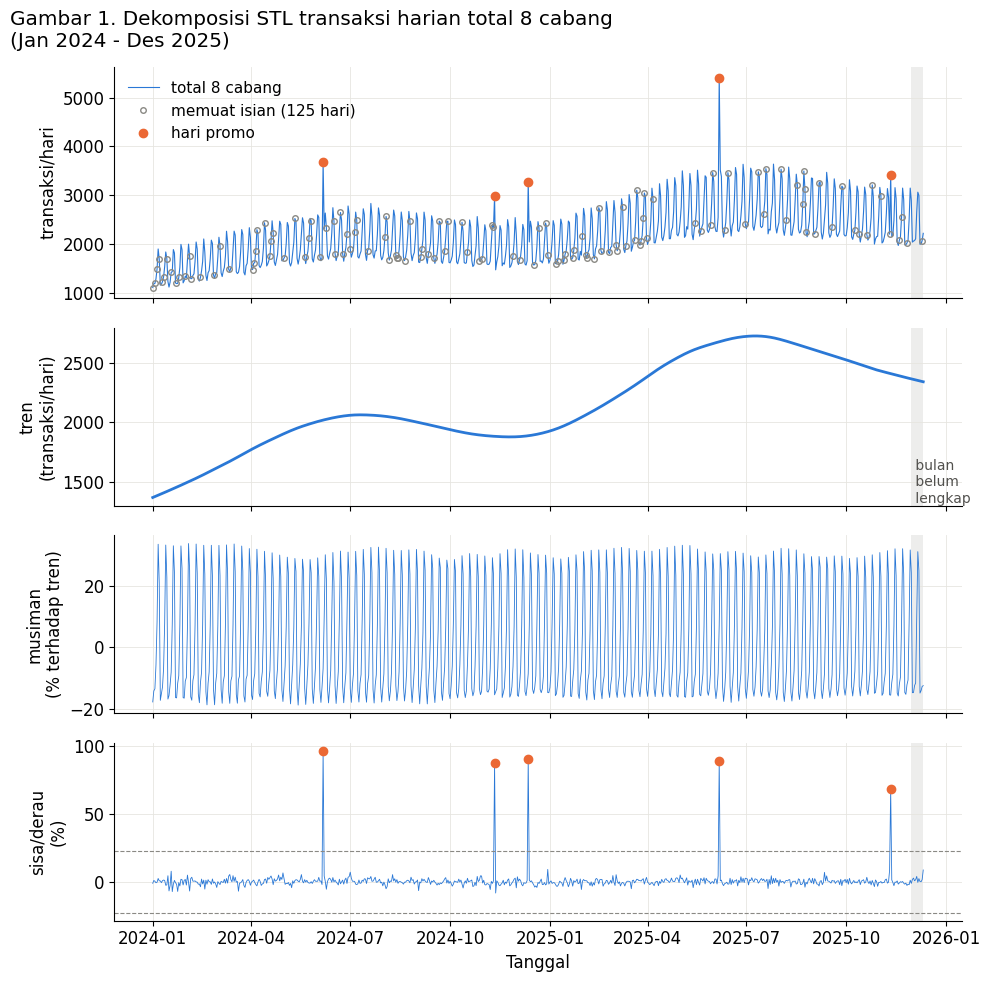

In [53]:
# Gambar 1: empat panel bertumpuk dengan sumbu waktu yang sama
fig, ax = plt.subplots(4, 1, figsize=(10, 10), sharex=True,
                       gridspec_kw={"height_ratios": [1.3, 1, 1, 1]})
pr, isi = komp.index.isin(PROMO), diisi.values

ax[0].plot(komp.index, komp["total"], color=BIRU, lw=0.8, label="total 8 cabang")
ax[0].plot(komp.index[isi], komp["total"][isi], "o", ms=4, mfc="none", mec=ABU, label=f"memuat isian ({isi.sum()} hari)")
ax[0].plot(komp.index[pr], komp["total"][pr], "o", ms=6, color=ORANYE, label="hari promo")
ax[0].set_ylabel("transaksi/hari")
ax[0].legend(loc="upper left", fontsize=11, frameon=False)

ax[1].plot(komp.index, komp["tren"], color=BIRU, lw=2)
ax[1].set_ylabel("tren\n(transaksi/hari)")

ax[2].plot(komp.index, (komp["musiman"] - 1) * 100, color=BIRU, lw=0.6)
ax[2].set_ylabel("musiman\n(% terhadap tren)")

ax[3].plot(komp.index, sisa, color=BIRU, lw=0.6)
ax[3].plot(komp.index[pr], sisa[pr], "o", ms=6, color=ORANYE)
for b in (-3, 3):
    ax[3].axhline(b * sisa.std(), color=ABU, lw=0.8, ls="--")
ax[3].set_ylabel("sisa/derau\n(%)")
ax[3].set_xlabel("Tanggal")

for a in ax:
    a.axvspan(AKHIR_LENGKAP, komp.index.max(), color=ABU, alpha=0.15, lw=0)
ax[1].text(AKHIR_LENGKAP, ax[1].get_ylim()[0], " bulan\n belum\n lengkap", fontsize=10, color=TEKS, va="bottom")
fig.suptitle("Gambar 1. Dekomposisi STL transaksi harian total 8 cabang\n(Jan 2024 - Des 2025)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIG / "gambar1_dekomposisi_stl.png", dpi=200, bbox_inches="tight")
plt.show()

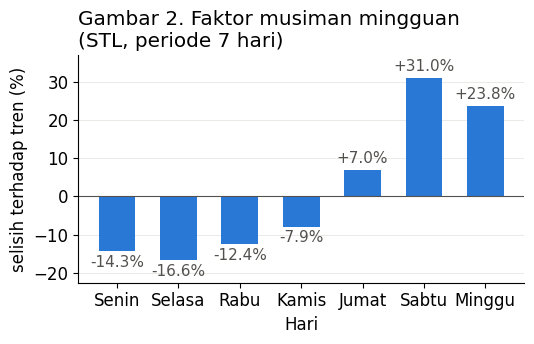

In [54]:
# Gambar 2: faktor musiman per hari dalam seminggu
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.bar(HARI, faktor_hari, color=BIRU, width=0.6)
ax.axhline(0, color=TEKS, lw=0.8)
for x, v in enumerate(faktor_hari):
    ax.text(x, v + (1 if v > 0 else -1), f"{v:+.1f}%", ha="center", va="bottom" if v > 0 else "top", fontsize=11, color=TEKS)
ax.set_ylabel("selisih terhadap tren (%)")
ax.set_xlabel("Hari")
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)
ax.set_ylim(faktor_hari.min() - 6, faktor_hari.max() + 6)
ax.set_title("Gambar 2. Faktor musiman mingguan\n(STL, periode 7 hari)", loc="left")
fig.tight_layout()
fig.savefig(FIG / "gambar2_faktor_mingguan.png", dpi=200, bbox_inches="tight")
plt.show()

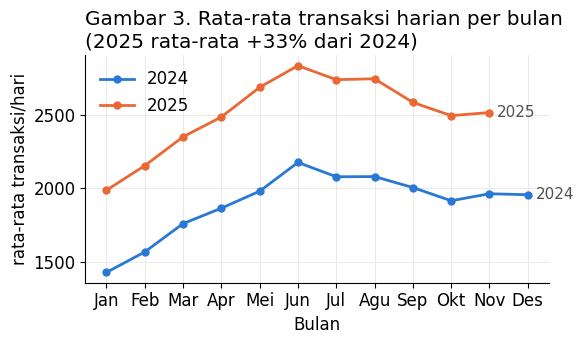

In [55]:
# Gambar 3: rata-rata transaksi/hari per bulan, 2024 vs 2025 (Des 2025 tidak lengkap, tidak digambar)
fig, ax = plt.subplots(figsize=(6, 3.6))
for th, warna in [("2024", BIRU), ("2025", ORANYE)]:
    b = bulanan[th]
    ax.plot(range(len(b)), b.values, "-o", color=warna, lw=2, ms=5, label=th)
    ax.text(len(b) - 1 + 0.2, b.values[-1], th, color=TEKS, va="center", fontsize=11)
ax.set_xticks(range(12), BULAN)
ax.set_ylabel("rata-rata transaksi/hari")
ax.set_xlabel("Bulan")
ax.legend(loc="upper left", frameon=False)
ax.set_title(f"Gambar 3. Rata-rata transaksi harian per bulan\n(2025 rata-rata {yoy['tumbuh_%'].mean():+.0f}% dari 2024)", loc="left")
fig.tight_layout()
fig.savefig(FIG / "gambar3_bulanan_yoy.png", dpi=200, bbox_inches="tight")
plt.show()

## Bagian B2 — Keluhan dan transaksi

In [56]:
# Hari valid: transaksi & keluhan terisi, bukan hari nol (Garut sudah dikoreksi di A9)
dk = bersih[~bersih["hari_nol"] & bersih["transaksi"].notna() & bersih["keluhan"].notna()].copy()
dk["tahun"] = dk["tanggal"].dt.year
dkl = dk[dk["tanggal"] <= AKHIR_LENGKAP]  # untuk agregat bulanan/tahunan

def per_1000(d):
    # Σkeluhan / Σtransaksi x 1000, bukan rata-rata rasio harian
    return d["keluhan"].sum() / d["transaksi"].sum() * 1000

print("baris valid:", len(dk))

baris valid: 5551


### B2.1 Tanpa memperhitungkan volume

In [57]:
# Total harian, hanya hari dengan 8 cabang valid
lengkap = dk.groupby("tanggal").size() == 8
hr = dk.groupby("tanggal")[["transaksi", "keluhan"]].sum()[lengkap]
hr["per_1000"] = hr["keluhan"] / hr["transaksi"] * 1000
hr["tahun"] = hr.index.year

# Agregat bulanan (bulan lengkap)
bln = dkl.groupby(dkl["tanggal"].dt.to_period("M"))[["transaksi", "keluhan"]].sum()
bln["per_1000"] = bln["keluhan"] / bln["transaksi"] * 1000

pd.DataFrame({
    "keluhan~transaksi": [hr["keluhan"].corr(hr["transaksi"]), bln["keluhan"].corr(bln["transaksi"])],
    "per_1000~transaksi": [hr["per_1000"].corr(hr["transaksi"]), bln["per_1000"].corr(bln["transaksi"])],
}, index=[f"harian ({len(hr)} hari)", f"bulanan ({len(bln)} bulan)"]).round(2)

,keluhan~transaksi,per_1000~transaksi
harian (586 hari),0.89,-0.38
bulanan (23 bulan),0.94,-0.82


In [58]:
# Korelasi di dalam tiap cabang (harian)
dk.assign(per_1000=dk["keluhan"] / dk["transaksi"] * 1000).groupby("cabang").apply(
    lambda g: pd.Series({"keluhan~transaksi": g["keluhan"].corr(g["transaksi"]),
                         "per_1000~transaksi": g["per_1000"].corr(g["transaksi"])}),
    include_groups=False).round(2)

,keluhan~transaksi,per_1000~transaksi
cabang,,
Bandung,0.72,-0.20
Bekasi,0.75,-0.15
Cimahi,0.61,-0.15
Cirebon,0.64,-0.16
Depok,0.66,-0.19
Garut,0.56,-0.14
Sumedang,0.54,-0.10
Tasikmalaya,0.55,-0.13


### B2.2 Setelah memperhitungkan volume

In [59]:
# Indeks Jan 2024 = 100
indeks = bln / bln.iloc[0] * 100
print("tingkat keluhan per 1000:", round(bln["per_1000"].iloc[0], 1), "->", round(bln["per_1000"].iloc[-1], 1))
print("per tahun:", dkl.groupby("tahun").apply(per_1000, include_groups=False).round(1).to_dict())
indeks.iloc[[0, 5, 11, 17, -1]].round(0)

tingkat keluhan per 1000: 65.7 -> 49.5
per tahun: {2024: 60.5, 2025: 53.8}


,transaksi,keluhan,per_1000
tanggal,,,
2024-01,100.0,100.0,100.0
2024-06,151.0,141.0,94.0
2024-12,141.0,121.0,86.0
2025-06,200.0,161.0,81.0
2025-11,177.0,133.0,75.0


In [60]:
# Elastisitas (kemiringan log keluhan terhadap log transaksi) dan korelasi setelah tren linear dibuang
x = np.arange(len(bln))
elastis = np.polyfit(np.log(bln["transaksi"]), np.log(bln["keluhan"]), 1)[0]
kemiringan = np.polyfit(x, bln["per_1000"], 1)[0]

def tanpa_tren(v):
    return v - np.polyval(np.polyfit(x, v, 1), x)

r_detrend = np.corrcoef(tanpa_tren(bln["per_1000"].values), tanpa_tren(bln["transaksi"].values))[0, 1]
print(f"elastisitas: {elastis:.2f} | perubahan per_1000 per bulan: {kemiringan:.2f} | korelasi tanpa tren: {r_detrend:.2f}")

elastisitas: 0.68 | perubahan per_1000 per bulan: -0.62 | korelasi tanpa tren: 0.19


In [61]:
# Per cabang 2024 vs 2025: apakah penurunan merata?
cab = dkl.groupby(["cabang", "tahun"]).apply(per_1000, include_groups=False).unstack()
cab["ubah_%"] = (cab[2025] / cab[2024] - 1) * 100
cab.sort_values(2024).round(1)

tahun,2024,2025,ubah_%
cabang,,,
Cirebon,55.4,48.6,-12.3
Cimahi,56.5,50.4,-10.8
Depok,57.5,51.8,-9.9
Tasikmalaya,60.5,53.2,-12.1
Sumedang,61.1,54.0,-11.6
Garut,61.5,54.4,-11.5
Bekasi,62.7,56.9,-9.4
Bandung,65.6,57.6,-12.1


In [62]:
# Hari promo dan hari dalam seminggu tidak mengubah tingkat keluhan
r = dk.assign(per_1000=dk["keluhan"] / dk["transaksi"] * 1000)
print("median per_1000 promo vs biasa:", round(r[r["promo"]]["per_1000"].median(), 1), "vs", round(r[~r["promo"]]["per_1000"].median(), 1))
r.groupby(r["tanggal"].dt.dayofweek)["per_1000"].median().set_axis(HARI).round(1)

median per_1000 promo vs biasa: 56.6 vs 56.3


Senin     56.7
Selasa    57.0
Rabu      55.5
Kamis     56.7
Jumat     56.7
Sabtu     55.9
Minggu    55.6
Name: per_1000, dtype: float64

### B2.3 Visualisasi

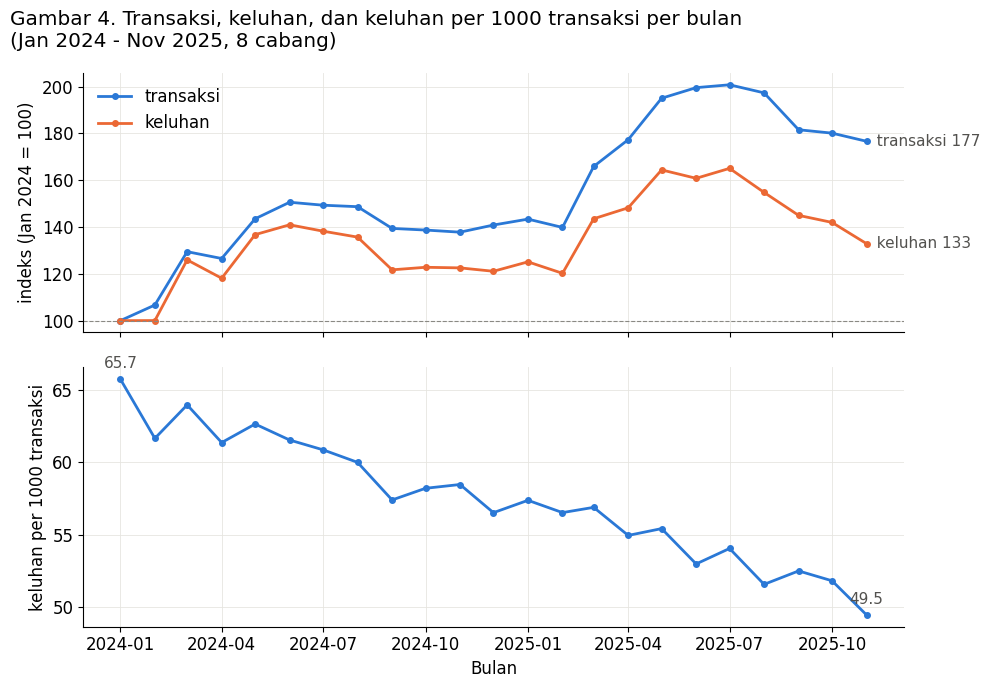

In [63]:
# Visualisasi 4: indeks transaksi & keluhan (atas) dan keluhan per 1000 transaksi (bawah), sumbu waktu sama
t = bln.index.to_timestamp()
fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for kol, warna, nama in [("transaksi", BIRU, "transaksi"), ("keluhan", ORANYE, "keluhan")]:
    ax[0].plot(t, indeks[kol], "-o", color=warna, lw=2, ms=4, label=nama)
    ax[0].text(t[-1], indeks[kol].iloc[-1], f"  {nama} {indeks[kol].iloc[-1]:.0f}", color=TEKS, va="center", fontsize=11)
ax[0].axhline(100, color=ABU, lw=0.8, ls="--")
ax[0].set_ylabel("indeks (Jan 2024 = 100)")
ax[0].legend(loc="upper left", frameon=False)

ax[1].plot(t, bln["per_1000"], "-o", color=BIRU, lw=2, ms=4)
for i in (0, len(bln) - 1):
    ax[1].annotate(f"{bln['per_1000'].iloc[i]:.1f}", (t[i], bln["per_1000"].iloc[i]), textcoords="offset points",
                   xytext=(0, 8), ha="center", fontsize=11, color=TEKS)
ax[1].set_ylabel("keluhan per 1000 transaksi")
ax[1].set_xlabel("Bulan")
fig.suptitle("Gambar 4. Transaksi, keluhan, dan keluhan per 1000 transaksi per bulan\n(Jan 2024 - Nov 2025, 8 cabang)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIG / "gambar4_indeks_keluhan.png", dpi=200, bbox_inches="tight")
plt.show()

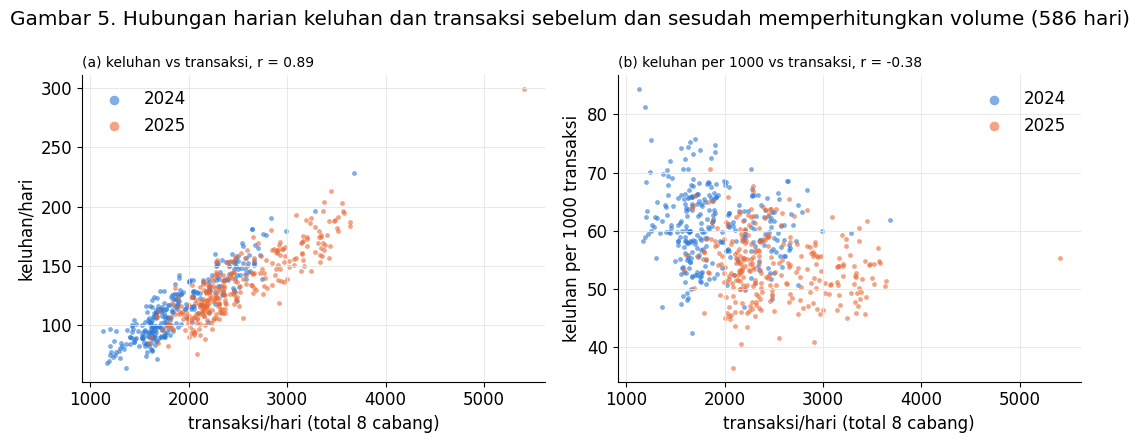

In [64]:
# visualisasi 5: total harian, keluhan vs transaksi (kiri) dan keluhan per 1000 vs transaksi (kanan)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for th, warna in [(2024, BIRU), (2025, ORANYE)]:
    s = hr[hr["tahun"] == th]
    ax[0].scatter(s["transaksi"], s["keluhan"], s=12, color=warna, alpha=0.6, lw=0, label=str(th))
    ax[1].scatter(s["transaksi"], s["per_1000"], s=12, color=warna, alpha=0.6, lw=0, label=str(th))
ax[0].set_ylabel("keluhan/hari")
ax[0].set_title(f"(a) keluhan vs transaksi, r = {hr['keluhan'].corr(hr['transaksi']):.2f}", loc="left", fontsize=10)
ax[1].set_ylabel("keluhan per 1000 transaksi")
ax[1].set_title(f"(b) keluhan per 1000 vs transaksi, r = {hr['per_1000'].corr(hr['transaksi']):.2f}", loc="left", fontsize=10)
for a, loc in zip(ax, ["upper left", "upper right"]):
    a.set_xlabel("transaksi/hari (total 8 cabang)")
    a.legend(loc=loc, frameon=False, markerscale=2)
fig.suptitle(f"Gambar 5. Hubungan harian keluhan dan transaksi sebelum dan sesudah memperhitungkan volume ({len(hr)} hari)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIG / "gambar5_scatter_keluhan.png", dpi=200, bbox_inches="tight")
plt.show()

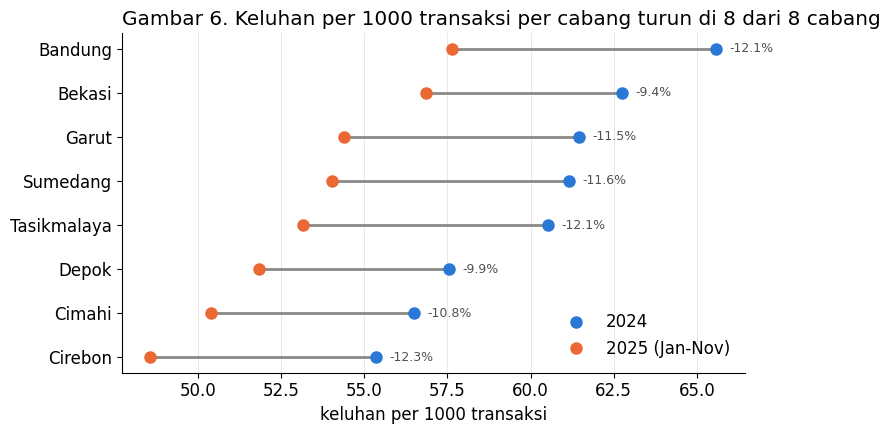

In [65]:
# visualisasi 6: keluhan per 1000 transaksi per cabang, 2024 vs 2025
c = cab.sort_values(2024)
y = np.arange(len(c))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hlines(y, c[2025], c[2024], color=ABU, lw=2)
ax.plot(c[2024], y, "o", color=BIRU, ms=8, label="2024")
ax.plot(c[2025], y, "o", color=ORANYE, ms=8, label="2025 (Jan-Nov)")
for yi, (a, b, u) in enumerate(zip(c[2024], c[2025], c["ubah_%"])):
    ax.text(a + 0.4, yi, f"{u:+.1f}%", va="center", fontsize=9, color=TEKS)
ax.set_yticks(y, c.index)
ax.set_xlabel("keluhan per 1000 transaksi")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=False)
ax.set_title("Gambar 6. Keluhan per 1000 transaksi per cabang turun di 8 dari 8 cabang", loc="left")
fig.tight_layout()
fig.savefig(FIG / "gambar6_per_cabang.png", dpi=200, bbox_inches="tight")
plt.show()